# 02 — Pooled detection results

            This notebook reports only the pooled binary normal-versus-fault experiment. The primary analysis uses the quality-controlled table with ambiguous duplicate keys excluded. A second table retains and flags duplicate keys solely for a pre-declared XGBoost sensitivity check. This notebook does not retrain models.

            The three active pooled split interpretations are chronological, building-held-out and nested-grouped. The pooled AHU-held-out assignment remains saved for traceability but is disabled and is not used here. Individual auditorium, hospital and office results are reported in Notebook 03.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load the matched pooled artefacts

In [2]:
BASELINE = ROOT / 'results' / 'quality_controlled' / 'exclude_ambiguous_keys' / 'baselines'
QUALITY_MAIN = ROOT / 'results' / 'quality_controlled' / 'exclude_ambiguous_keys'
QUALITY_RETAIN = ROOT / 'results' / 'quality_controlled' / 'retain_flagged_keys'
CLEANED_MAIN = ROOT / 'data' / 'interim' / 'cleaned' / 'cleaned_ahu.csv'
CLEANED_RETAIN = ROOT / 'data' / 'interim' / 'cleaned' / 'cleaned_ahu_retain_flagged_keys.csv'
ACTIVE_DESIGNS = ['chronological', 'building_held_out', 'nested_grouped']
require(
    BASELINE / 'baseline_metrics_summary.csv',
    QUALITY_MAIN / 'quality_detection_metrics_by_fold.csv', QUALITY_RETAIN / 'quality_detection_metrics_by_fold.csv',
    CLEANED_MAIN, CLEANED_RETAIN,
)
baseline = pd.read_csv(BASELINE / 'baseline_metrics_summary.csv')
quality_main = pd.read_csv(QUALITY_MAIN / 'quality_detection_metrics_by_fold.csv')
quality_retain = pd.read_csv(QUALITY_RETAIN / 'quality_detection_metrics_by_fold.csv')
main_data_rows = len(pd.read_csv(CLEANED_MAIN, usecols=['building']))
retained_data_rows = len(pd.read_csv(CLEANED_RETAIN, usecols=['building']))
baseline = baseline[baseline['design'].isin(ACTIVE_DESIGNS)].copy()
quality_main = quality_main[quality_main['design'].isin(ACTIVE_DESIGNS)].copy()
quality_retain = quality_retain[quality_retain['design'].isin(ACTIVE_DESIGNS)].copy()
print('Observations in primary analysis table (ambiguous duplicate keys removed):', main_data_rows)
print('Observations in duplicate-sensitivity table (duplicate keys retained and flagged):', retained_data_rows)
print('Metric records in primary analysis results:', len(quality_main))
print('Metric records in duplicate-sensitivity results:', len(quality_retain))
print('A metric record represents one model, split design and fold; it is not a data row.')

Observations in primary analysis table (ambiguous duplicate keys removed): 354587
Observations in duplicate-sensitivity table (duplicate keys retained and flagged): 354955
Metric records in primary analysis results: 36
Metric records in duplicate-sensitivity results: 36
A metric record represents one model, split design and fold; it is not a data row.


## 2. Baseline comparison

In [3]:
display(baseline[['design', 'baseline', 'folds', 'mean_f1', 'mean_balanced_accuracy', 'mean_false_positive_rate']].round(3))

,design,baseline,folds,mean_f1,mean_balanced_accuracy,mean_false_positive_rate
0,building_held_out,actuator_pump_only,3,0.029,0.502,0.012
1,building_held_out,majority_class,3,0.000,0.500,0.000
2,building_held_out,normal_range_rule,3,0.429,0.581,0.346
3,chronological,actuator_pump_only,1,0.398,0.617,0.037
4,chronological,majority_class,1,0.000,0.500,0.000
5,chronological,normal_range_rule,1,0.178,0.510,0.101
6,nested_grouped,actuator_pump_only,5,0.492,0.648,0.094
7,nested_grouped,majority_class,5,0.000,0.500,0.000
8,nested_grouped,normal_range_rule,5,0.448,0.628,0.080


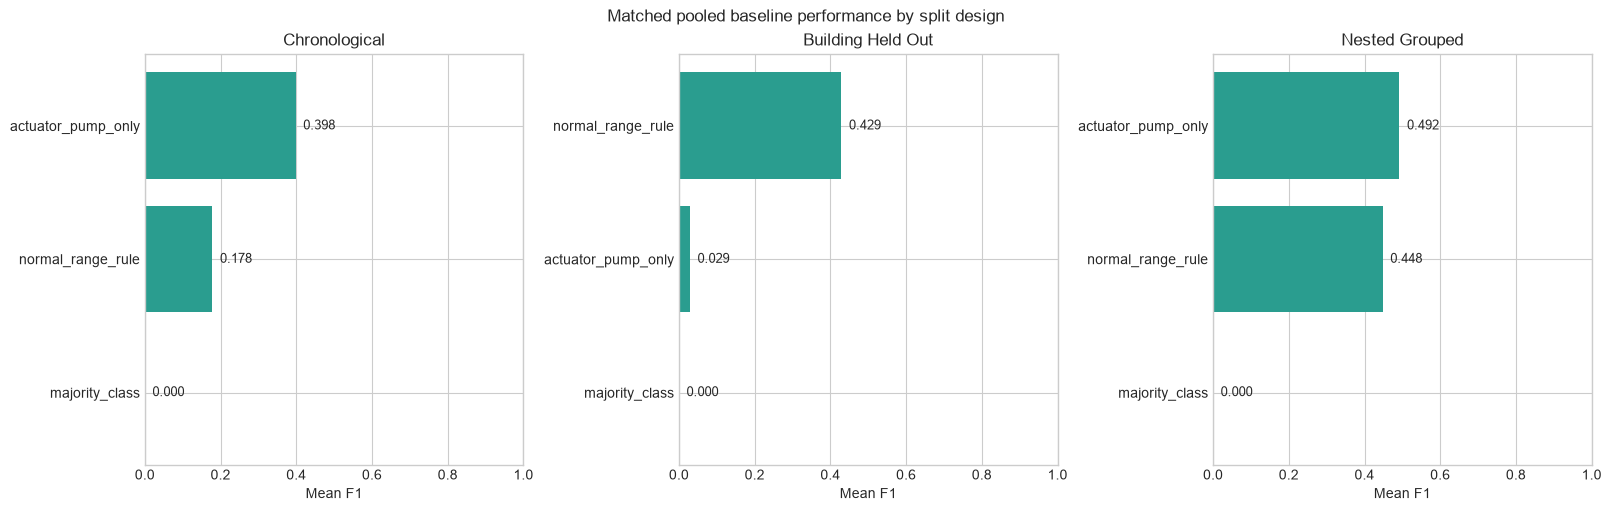

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, constrained_layout=True)
for ax, design in zip(axes, ACTIVE_DESIGNS):
    plot_data = baseline[baseline['design'].eq(design)].sort_values('mean_f1')
    ax.barh(plot_data['baseline'], plot_data['mean_f1'], color=COLORS['accent'])
    ax.set_title(design.replace('_', ' ').title())
    ax.set_xlim(0, 1)
    ax.set_xlabel('Mean F1')
    for index, value in enumerate(plot_data['mean_f1']):
        ax.text(value + 0.02, index, f'{value:.3f}', va='center', fontsize=9)
fig.suptitle('Matched pooled baseline performance by split design')
plt.show()

These baselines are evaluated on the same duplicate-excluded table and active split assignments as the primary models. The majority classifier is a lower bound, the normal-range rule is transparent, and the actuator/pump-only baseline tests whether a small control subset is sufficient. The split-specific panels avoid treating different generalisation questions as one interchangeable score.

## 3. Main pooled model comparison

In [5]:
model_summary = quality_main.groupby(['design', 'model'], as_index=False).agg(
    folds=('fold', 'nunique'), mean_f1=('f1', 'mean'), mean_macro_f1=('macro_f1', 'mean'),
    mean_balanced_accuracy=('balanced_accuracy', 'mean'), mean_precision=('precision', 'mean'),
    mean_recall=('recall', 'mean'), mean_false_positive_rate=('false_positive_rate', 'mean'),
    mean_coverage=('coverage', 'mean')
)
display(model_summary.round(3))

,design,model,folds,mean_f1,mean_macro_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate,mean_coverage
0,building_held_out,isolation_forest,3,0.148,0.472,0.536,0.338,0.121,0.048,1.000
1,building_held_out,lstm_autoencoder,3,0.133,0.462,0.521,0.310,0.092,0.050,0.993
2,building_held_out,normal_range_rule,3,0.460,0.494,0.560,0.365,0.678,0.558,1.000
3,building_held_out,xgboost,3,0.284,0.534,0.584,0.492,0.286,0.118,1.000
4,chronological,isolation_forest,1,0.034,0.428,0.500,0.304,0.018,0.017,1.000
5,chronological,lstm_autoencoder,1,0.091,0.441,0.486,0.219,0.057,0.085,0.987
6,chronological,normal_range_rule,1,0.278,0.498,0.498,0.293,0.264,0.268,1.000
7,chronological,xgboost,1,0.823,0.863,0.909,0.703,0.994,0.176,1.000
8,nested_grouped,isolation_forest,5,0.087,0.442,0.519,0.708,0.047,0.010,1.000
9,nested_grouped,lstm_autoencoder,5,0.027,0.409,0.503,0.468,0.014,0.008,0.994


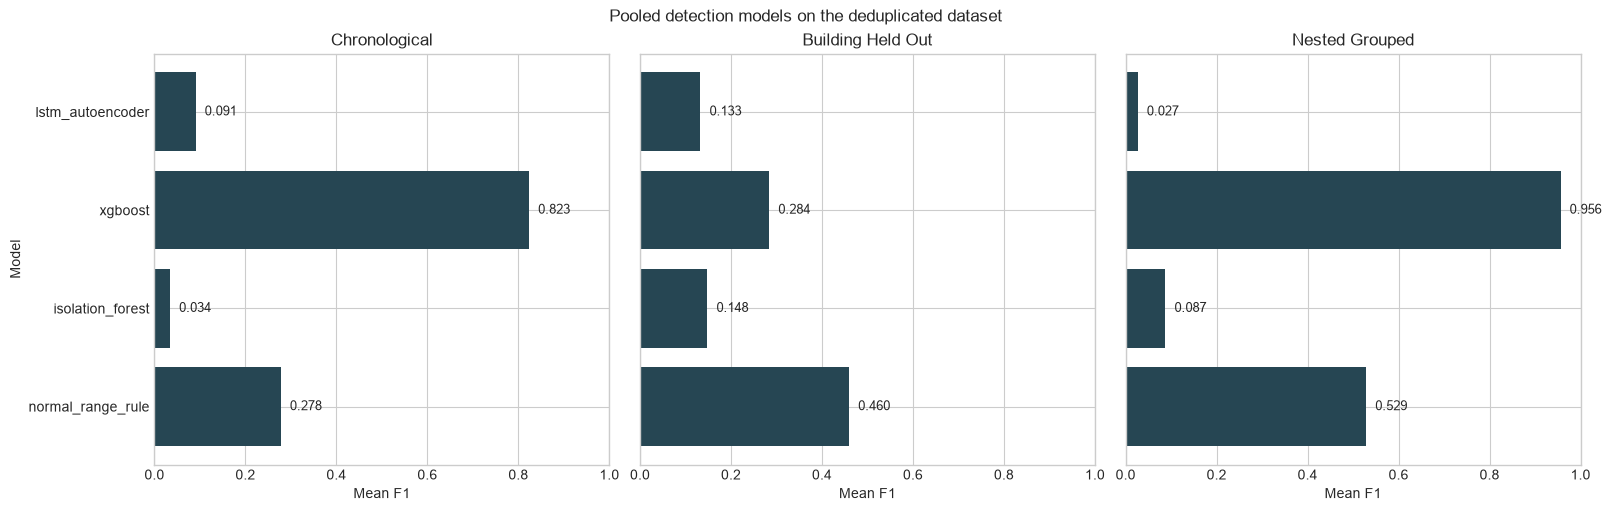

In [6]:
models = ['normal_range_rule', 'isolation_forest', 'xgboost', 'lstm_autoencoder']
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True, constrained_layout=True)
for ax, design in zip(axes, ACTIVE_DESIGNS):
    plot_data = model_summary[(model_summary['design'].eq(design)) & (model_summary['model'].isin(models))]
    plot_data = plot_data.set_index('model').reindex(models).reset_index()
    ax.barh(plot_data['model'], plot_data['mean_f1'], color=COLORS['dark'])
    ax.set_title(design.replace('_', ' ').title())
    ax.set_xlim(0, 1)
    ax.set_xlabel('Mean F1')
    for index, value in enumerate(plot_data['mean_f1']):
        if pd.notna(value):
            ax.text(value + 0.02, index, f'{value:.3f}', va='center', fontsize=9)
axes[0].set_ylabel('Model')
fig.suptitle('Pooled detection models on the deduplicated dataset')
plt.show()

XGBoost is the principal supervised model. Isolation Forest and the LSTM are retained as methodological comparisons, while the normal-range rule provides the transparent statistical reference. LSTM coverage is shown explicitly because rows without a complete contiguous sequence are not silently scored as normal.

## 4. XGBoost duplicate-policy sensitivity

In [7]:
def xgb_summary(frame, policy):
    result = frame[frame['model'].eq('xgboost')].groupby('design', as_index=False).agg(
        mean_f1=('f1', 'mean'), mean_balanced_accuracy=('balanced_accuracy', 'mean'),
        mean_false_positive_rate=('false_positive_rate', 'mean')
    )
    result['policy'] = policy
    return result
duplicate_comparison = pd.concat([
    xgb_summary(quality_main, 'duplicates excluded'),
    xgb_summary(quality_retain, 'duplicates retained and flagged'),
], ignore_index=True)
display(duplicate_comparison.round(3))

,design,mean_f1,mean_balanced_accuracy,mean_false_positive_rate,policy
0,building_held_out,0.284,0.584,0.118,duplicates excluded
1,chronological,0.823,0.909,0.176,duplicates excluded
2,nested_grouped,0.956,0.965,0.006,duplicates excluded
3,building_held_out,0.267,0.570,0.116,duplicates retained and flagged
4,chronological,0.820,0.907,0.180,duplicates retained and flagged
5,nested_grouped,0.955,0.964,0.007,duplicates retained and flagged


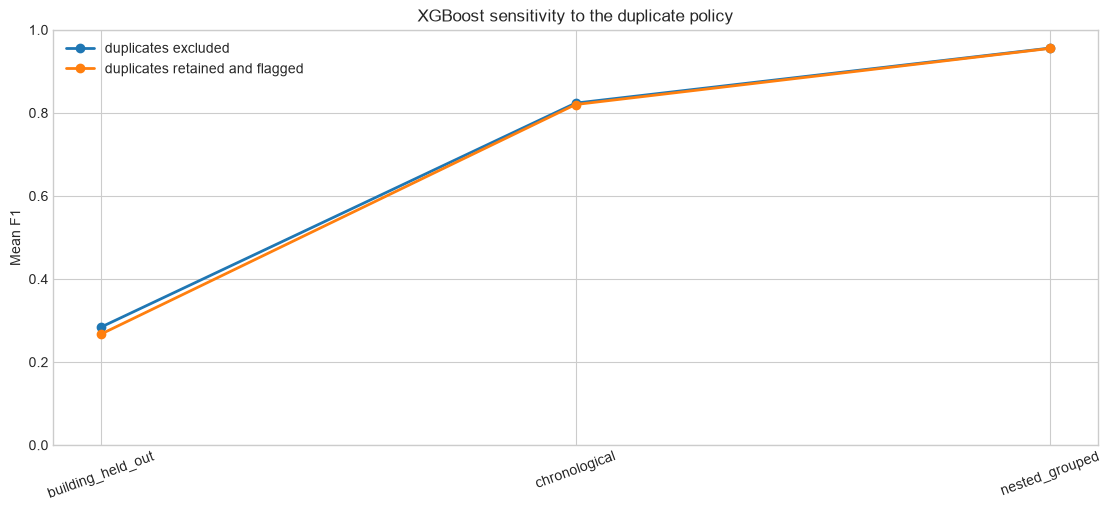

In [8]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for policy, group in duplicate_comparison.groupby('policy'):
    ax.plot(group['design'], group['mean_f1'], marker='o', linewidth=2, label=policy)
ax.set_ylim(0, 1)
ax.set_ylabel('Mean F1')
ax.set_title('XGBoost sensitivity to the duplicate policy')
ax.tick_params(axis='x', rotation=20)
ax.legend()
plt.show()

## 5. Interpretation of pooled results

The duplicate-excluded run is the primary pooled result. The duplicate-retained run is a sensitivity analysis, not a second opportunity to select a more favourable model. The results describe performance under these labelled historical buildings and split designs; they do not establish production performance without target-building calibration.

## 6. What this notebook does and does not establish

In [9]:
conclusions = pd.DataFrame([
    ['Dataset policy', 'Duplicate-excluded table is primary; retained duplicates are sensitivity only', 'The duplicate decision is visible and not chosen after inspecting scores'],
    ['Model selection', 'XGBoost is the main supervised comparison', 'Other models remain useful as methodological references'],
    ['Generalisation', 'Scores vary by split design', 'Temporal and cross-building transfer should not be conflated'],
    ['Deployment', 'Historical test evidence only', 'Target-building calibration and monitoring are still required'],
], columns=['question', 'observed result', 'responsible_interpretation'])
display(conclusions)

,question,observed result,responsible_interpretation
0,Dataset policy,Duplicate-excluded table is primary; retained ...,The duplicate decision is visible and not chos...
1,Model selection,XGBoost is the main supervised comparison,Other models remain useful as methodological r...
2,Generalisation,Scores vary by split design,Temporal and cross-building transfer should no...
3,Deployment,Historical test evidence only,Target-building calibration and monitoring are...


## Secondary comparison: raw sensors, engineered predictors and symptoms-only

This focused XGBoost comparison asks two separate questions using the same cleaned rows and test assignments. Raw sensors only (19 columns) versus the full engineered set (88 columns) measures the value added by Phase 5 relationships and past-only temporal features. Symptoms-only is a separate robustness check that removes direct actuator, equipment-state and pump-status channels. These are feature ablations, not additional baselines or replacements for the practical model.

,variant,design,folds,feature_count,mean_f1,mean_macro_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate,test_rows
0,default_bms_signals,building_held_out,3,88,0.284,0.534,0.584,0.492,0.286,0.118,354587
1,default_bms_signals,chronological,1,88,0.823,0.863,0.909,0.703,0.994,0.176,70935
2,default_bms_signals,nested_grouped,5,88,0.956,0.966,0.965,0.986,0.936,0.006,354587
3,raw_sensor_only,building_held_out,3,19,0.495,0.653,0.677,0.753,0.441,0.088,354587
4,raw_sensor_only,chronological,1,19,0.796,0.840,0.888,0.673,0.973,0.198,70935
5,raw_sensor_only,nested_grouped,5,19,0.958,0.967,0.967,0.974,0.947,0.013,354587
6,symptom_only,building_held_out,3,35,0.471,0.638,0.643,0.713,0.408,0.122,354587
7,symptom_only,chronological,1,35,0.767,0.820,0.859,0.660,0.915,0.198,70935
8,symptom_only,nested_grouped,5,35,0.941,0.955,0.956,0.959,0.932,0.020,354587


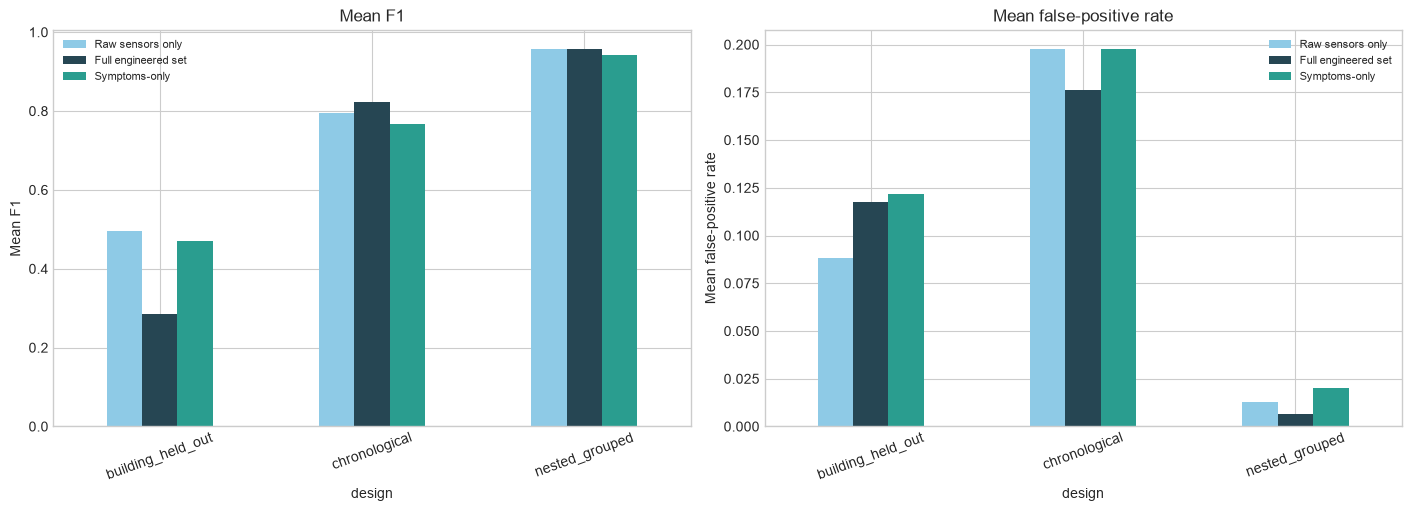

variant,Full engineered set,Raw sensors only,Engineered minus raw F1
design,,,
building_held_out,0.284,0.495,-0.211
chronological,0.823,0.796,0.028
nested_grouped,0.956,0.958,-0.002


In [10]:
sensitivity_path = Path('../results/feature_sensitivity/pooled_xgboost_feature_sensitivity_summary.csv')
if not sensitivity_path.exists():
    sensitivity_path = Path('results/feature_sensitivity/pooled_xgboost_feature_sensitivity_summary.csv')
sensitivity = pd.read_csv(sensitivity_path)
display(sensitivity.round(3))

plot_data = sensitivity.copy()
plot_data['variant_label'] = plot_data['variant'].map({
    'raw_sensor_only': 'Raw sensors only',
    'default_bms_signals': 'Full engineered set',
    'symptom_only': 'Symptoms-only',
})
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for axis, metric, title in zip(axes, ['mean_f1', 'mean_false_positive_rate'], ['Mean F1', 'Mean false-positive rate'], strict=True):
    table = plot_data.pivot(index='design', columns='variant_label', values=metric)
    table = table.reindex(columns=['Raw sensors only', 'Full engineered set', 'Symptoms-only'])
    table.plot.bar(ax=axis, color=['#8ecae6', COLORS['dark'], COLORS['accent']])
    axis.set_title(title)
    axis.set_ylabel(title)
    axis.tick_params(axis='x', rotation=20)
    axis.legend(fontsize=8)
plt.show()

engineering = (plot_data[plot_data['variant'].isin(['raw_sensor_only', 'default_bms_signals'])]
    .pivot(index='design', columns='variant', values='mean_f1')
    .rename(columns={'raw_sensor_only': 'Raw sensors only', 'default_bms_signals': 'Full engineered set'}))
engineering['Engineered minus raw F1'] = engineering['Full engineered set'] - engineering['Raw sensors only']
display(engineering.round(3))

Interpret the result by split rather than averaging across all designs. The raw-sensor versus full-engineered comparison is the evidence for whether Phase 5 relationships and temporal features add value. Here, engineering improves the chronological result slightly, is essentially neutral under nested grouped testing, and is weaker than raw sensors under building-held-out transfer. Therefore feature engineering is useful in some deployment settings but is not a universal performance improvement. A lower symptoms-only score indicates that direct BMS state signals contribute useful information; it does not by itself prove leakage. The full engineered set remains the pre-declared practical headline, while both ablations are retained as sensitivity evidence.

## Single-feature held-out dependence check

This audit tests the concern that one sensor might reveal the label by itself. Each default feature is evaluated alone on held-out rows from the same active pooled folds. Missing values are filled with that fold's training median only. The direction-free AUC is close to 0.5 when a feature does not separate normal and fault rows by itself; values close to 1 would indicate a strong one-feature shortcut. This is supporting evidence, not a replacement for the multivariate model evaluation.

,feature,family,folds,valid_folds,mean_absolute_auc,median_absolute_auc,max_absolute_auc
0,temporal__past_mean_24__return_temperature,past_rolling_mean,9,9,0.667,0.659,0.816
1,sensor__return_temperature,raw_sensor,9,9,0.679,0.665,0.812
2,temporal__past_mean_3__return_temperature,past_rolling_mean,9,9,0.673,0.663,0.810
3,relationship__return_setpoint_residual,relationship,9,9,0.645,0.632,0.803
4,relationship__heating_pump_any_on,pump_relationship,9,8,0.647,0.641,0.787
5,relationship__supply_return_abs_delta,relationship,9,9,0.589,0.568,0.746
6,temporal__past_mean_24__setpoint_temperature,past_rolling_mean,9,9,0.597,0.568,0.711
7,sensor__setpoint_temperature,raw_sensor,9,9,0.594,0.578,0.707
8,temporal__past_mean_3__setpoint_temperature,past_rolling_mean,9,9,0.594,0.577,0.707
9,sensor__heating_pump_total,raw_sensor,9,7,0.640,0.636,0.689


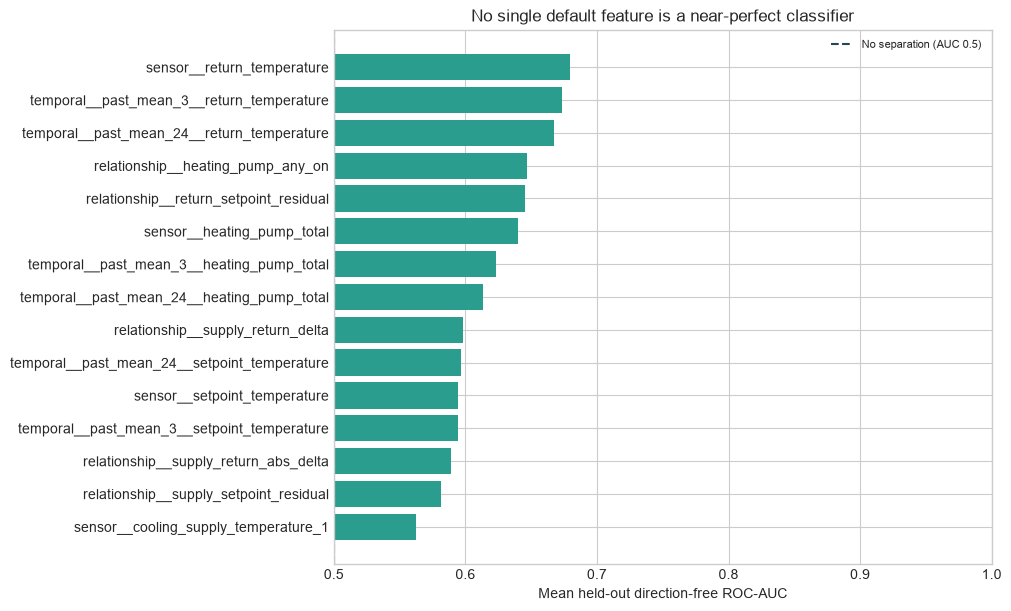

Highest mean one-feature AUC: 0.679
Highest fold-level one-feature AUC: 0.816


In [11]:
dependence_path = ROOT / 'results' / 'feature_dependence' / 'univariate_feature_auc_summary.csv'
require(dependence_path)
dependence = pd.read_csv(dependence_path)
display(dependence.head(15).round(3))

top = dependence.head(15).sort_values('mean_absolute_auc')
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.barh(top['feature'], top['mean_absolute_auc'], color=COLORS['accent'])
ax.axvline(0.5, color=COLORS['dark'], linestyle='--', label='No separation (AUC 0.5)')
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('Mean held-out direction-free ROC-AUC')
ax.set_title('No single default feature is a near-perfect classifier')
ax.legend(fontsize=8)
plt.show()

print(f"Highest mean one-feature AUC: {dependence['mean_absolute_auc'].max():.3f}")
print(f"Highest fold-level one-feature AUC: {dependence['max_absolute_auc'].max():.3f}")

The strongest individual feature is informative but not a complete detector: its mean and maximum held-out AUC remain below a near-perfect shortcut. The high multivariate score therefore reflects information combined across signals, relationships and past-only features. This check does not claim that the model is independent of every feature, nor does it rule out interactions between features; those are why the feature-variant sensitivity comparison remains included.